AI-Based Medical Report Analyzer using NLP & Machine Learning

In [53]:
# Importing Libraries and Models :-
import pandas as pd
import numpy as np
import re

# ML Models
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier

#Evaluation
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

**DataSet Overview:**

This section provides the basic information about the dataset.

In [54]:
# Load Dataset :-
df = pd.read_csv("dataset/mtsamples.csv")

df.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [55]:
# Basic Information
df.info()
print("\n")
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Unnamed: 0         4999 non-null   int64
 1   description        4999 non-null   str  
 2   medical_specialty  4999 non-null   str  
 3   sample_name        4999 non-null   str  
 4   transcription      4966 non-null   str  
 5   keywords           3931 non-null   str  
dtypes: int64(1), str(5)
memory usage: 16.4 MB




,Unnamed: 0
count,4999.000000
mean,2499.000000
std,1443.231328
min,0.000000
25%,1249.500000
50%,2499.000000
75%,3748.500000
max,4998.000000


**Data Cleaning**

In [56]:
df = df.dropna(subset=["transcription"])
df["medical_specialty"] = df["medical_specialty"].str.strip()

In [57]:
# Remove the duplicate transcriptions
df = df.drop_duplicates(subset=["transcription"])

In [58]:
# Specialties having at least 50 records 

counts = df["medical_specialty"].value_counts()
df = df[df["medical_specialty"].isin(counts[counts >= 50].index)].copy()

In [59]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["transcription"].apply(clean_text)
    

In [60]:
# Check missing values after cleaning

df.isnull().sum()

Unnamed: 0             0
description            0
medical_specialty      0
sample_name            0
transcription          0
keywords             365
clean_text             0
dtype: int64

**Data Analysis:**
Understand and visualize the dataset distributions and Feature Distribution.

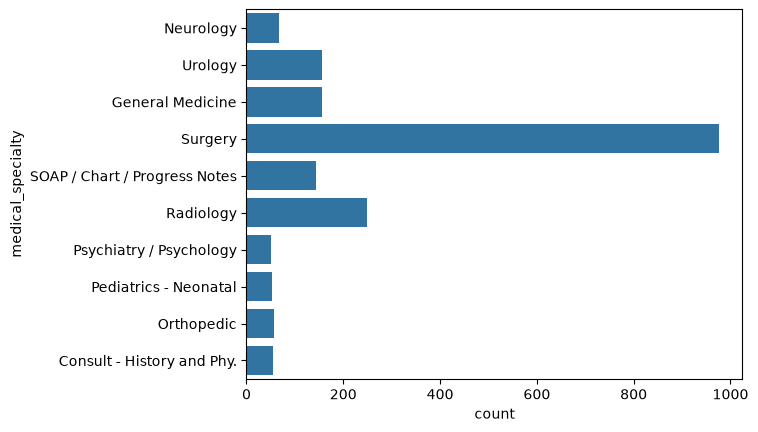

In [61]:

sns.countplot(y=df["medical_specialty"])
plt.show()

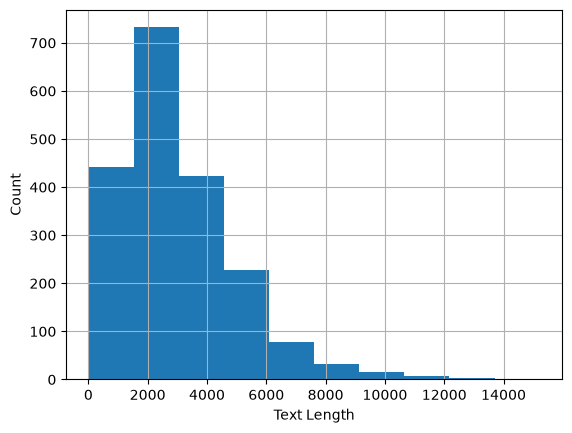

In [62]:
df["transcription"].str.len().hist()

plt.xlabel("Text Length")
plt.ylabel("Count")
plt.show()

**Training And Test Split:**
The Dataset is divided into traning (80%) and testing (20%).

In [63]:
# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["medical_specialty"],
    test_size=0.2, random_state=42, stratify=df["medical_specialty"],
)

In [64]:

# 3. TF-IDF
tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1, 2),
                        min_df=2, sublinear_tf=True, stop_words="english")
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

**Model Training :**
Train multiple Machine Learning Model 

In [65]:
# Random Forest Classifier
rm = RandomForestClassifier(n_estimators=100, random_state=42)
rm.fit(X_train_vec, y_train)
preds_rm = rm.predict(X_test_vec)

acc_rm = accuracy_score(y_test, preds_rm) * 100

In [66]:
# SVM
sm = LinearSVC()
sm.fit(X_train_vec, y_train)
preds_sm = sm.predict(X_test_vec)

acc_sm = accuracy_score(y_test, preds_sm) * 100

In [67]:
# Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)
preds_lr = lr.predict(X_test_vec)

acc_lr = accuracy_score(y_test, preds_lr) * 100

In [68]:
# Naive Bayes
nv = MultinomialNB()
nv.fit(X_train_vec, y_train)
preds_nv = nv.predict(X_test_vec)

acc_nv = accuracy_score(y_test, preds_nv) * 100

In [69]:
# SGD Classifier
sgd = SGDClassifier(loss="log_loss", random_state=42)
sgd.fit(X_train_vec, y_train)
preds_sgd = sgd.predict(X_test_vec)

acc_sgd = accuracy_score(y_test, preds_sgd) * 100


**Model Evaluation:**
Evaluate models using accuracy, confusion matrix, and classification.

In [70]:
def evaluate_model(name, y_test, y_pred):
    print(f"--- {name} ---")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("\n")

# Evaluate all Models

evaluate_model("Random Forest", y_test, preds_rm)
evaluate_model("SVM Classifier", y_test, preds_sm)
evaluate_model("Logistic Regression", y_test, preds_lr)
evaluate_model("Naive Bayes", y_test, preds_nv)
evaluate_model("SGD Classifier", y_test, preds_sgd)

--- Random Forest ---
Accuracy: 0.7913486005089059
Confusion Matrix:
 [[  1   8   0   1   0   0   0   0   1   0]
 [  0  28   0   0   0   0   0   4   0   0]
 [  0   3   3   1   0   0   1   4   1   0]
 [  0   4   0   1   0   0   1   1   3   1]
 [  0   8   0   0   1   0   1   0   0   0]
 [  0   3   0   0   0   6   0   0   1   0]
 [  0   0   0   0   0   0  49   0   1   0]
 [  0   5   0   0   0   0   2  20   2   0]
 [  1   0   0   0   0   0   0   0 195   0]
 [  0   2   0   0   0   0   2   0  20   7]]
Classification Report:
                                precision    recall  f1-score   support

   Consult - History and Phy.       0.50      0.09      0.15        11
             General Medicine       0.46      0.88      0.60        32
                    Neurology       1.00      0.23      0.38        13
                   Orthopedic       0.33      0.09      0.14        11
        Pediatrics - Neonatal       1.00      0.10      0.18        10
      Psychiatry / Psychology       1.00      0.

c:\Users\hp\Desktop\Medical_Report_Analyzer\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\Desktop\Medical_Report_Analyzer\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\hp\Desktop\Medical_Report_Analyzer\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

**Model Comparison:**
Comparing accuracy for all models.

C:\Users\hp\AppData\Local\Temp\ipykernel_7912\3729691744.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results_df, palette='magma')


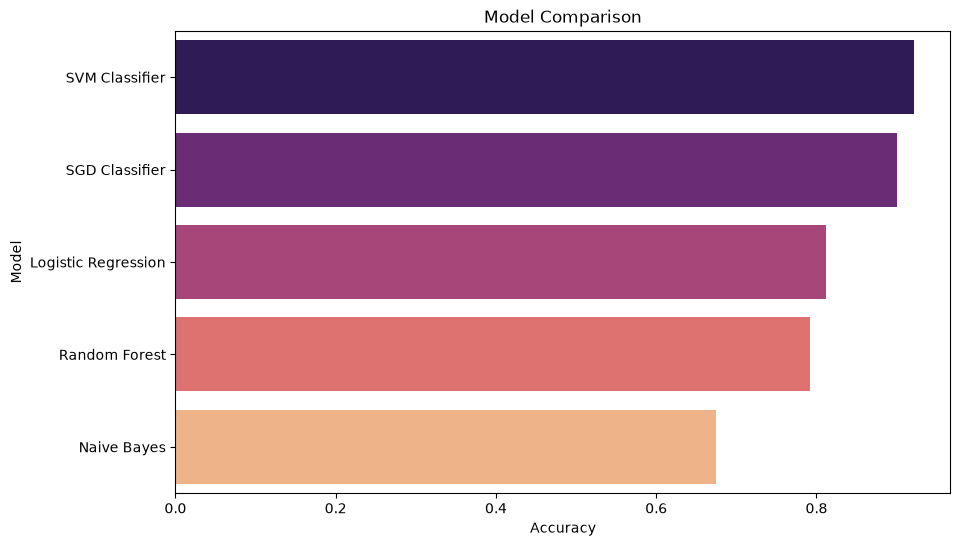

In [71]:
# Model Comparison Visualization
results = {
    "Random Forest": accuracy_score(y_test, preds_rm),
    "SVM Classifier": accuracy_score(y_test, preds_sm),
    "Logistic Regression": accuracy_score(y_test, preds_lr),
    "Naive Bayes": accuracy_score(y_test, preds_nv),
    "SGD Classifier": accuracy_score(y_test, preds_sgd)
    
}

results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])
results_df = results_df.sort_values(by='Accuracy', ascending=False)


# Bar Plot :-
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette='magma')
plt.title("Model Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.show()

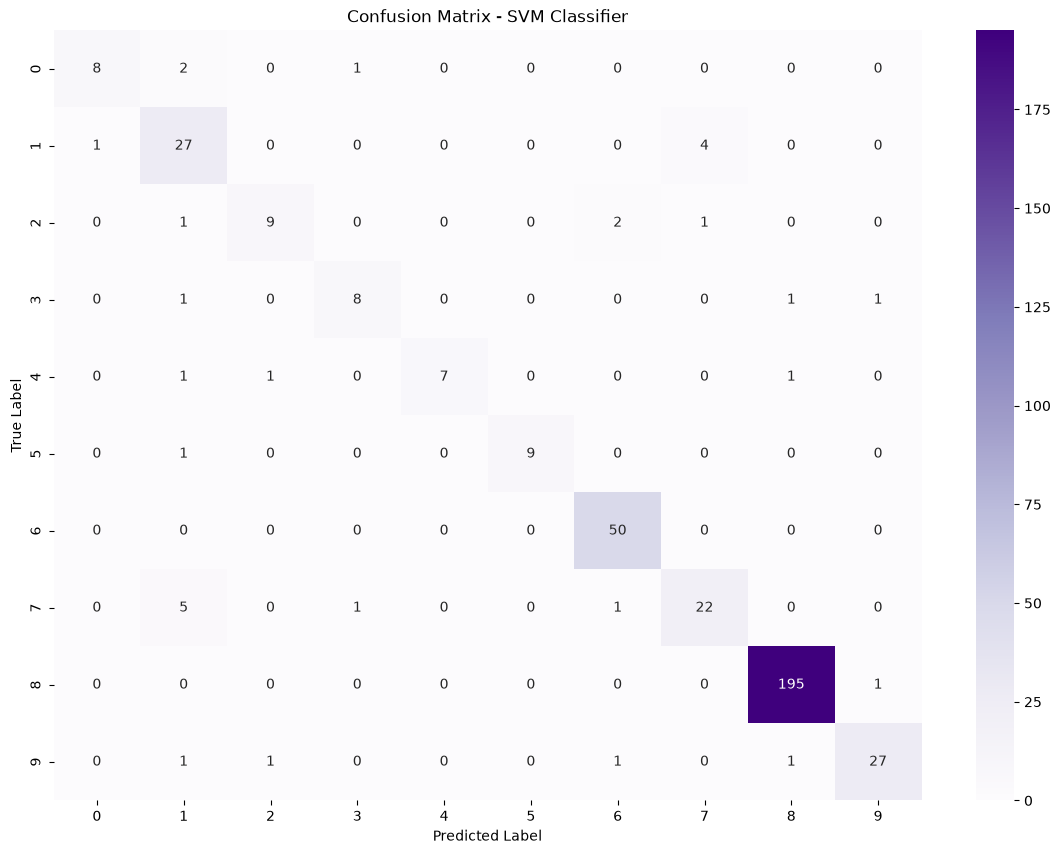

In [72]:
# SGD Classifier Confusion Matrix
plt.figure(figsize=(14,10))
sns.heatmap(confusion_matrix(y_test, preds_sm), annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - SVM Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**Final Prediction:**
Testing the model with new medical Report.

In [73]:
new_report = input("Enter Medical Report Transcription: ")

cleaned_report = clean_text(new_report)
report_vector = tfidf.transform([cleaned_report])

print("SVM Prediction:", sm.predict(report_vector)[0])

SVM Prediction: General Medicine


In [74]:
test_reports = [
    """A 70-year-old male presents with sudden facial drooping,
    weakness in the right arm, and difficulty speaking.
    CT scan of the brain is performed. Neurological examination
    suggests an acute stroke.""",

    """A 58-year-old male presents with frequent urination,
    weak urinary stream, and difficulty emptying his bladder.
    Examination suggests benign prostatic enlargement.""",

    """A 35-year-old patient presents with severe right lower
    abdominal pain, nausea, and vomiting. Acute appendicitis
    is suspected and laparoscopic appendectomy is planned.""",

    """Chest X-ray reveals a patchy opacity in the right
    lower lung field. No pleural effusion is identified.""",

    """A 3-day-old newborn presents with poor feeding,
    mild jaundice, and lethargy. Serum bilirubin testing
    is requested.""",

    """A 52-year-old patient presents with increased thirst,
    frequent urination, and fatigue. Blood tests reveal
    elevated fasting blood glucose and HbA1c levels.""",

    """A 42-year-old male presents with knee pain and swelling
    following a sports injury. Examination reveals tenderness
    and restricted range of motion.""",
]

for i, report in enumerate(test_reports, start=1):
    cleaned_report = clean_text(report)
    report_vector = tfidf.transform([cleaned_report])
    prediction = sm.predict(report_vector)[0]

    print(f"Report {i} Prediction: {prediction}")

Report 1 Prediction: Surgery
Report 2 Prediction: Urology
Report 3 Prediction: Surgery
Report 4 Prediction: Radiology
Report 5 Prediction: Radiology
Report 6 Prediction: Surgery
Report 7 Prediction: Orthopedic


Import

In [76]:

import joblib

# Save the trained TF-IDF vectorizer and SVM model
joblib.dump(
    {
        "tfidf": tfidf,
        "model": sm
    },
    "medical_report_svm.pkl"
)

print("SVM model and TF-IDF vectorizer saved successfully!")


SVM model and TF-IDF vectorizer saved successfully!
